Install libraries

In [1]:

!pip -q install -U pymupdf transformers tokenizers sentencepiece


Upload PDF and extract clean text

In [2]:
import fitz
import re
import json
from pathlib import Path
from google.colab import files

output_dir = Path("/content/luxembourg_imf")
output_dir.mkdir(exist_ok=True)

uploaded = files.upload()
pdf_path = next(
    (name for name in uploaded if name.lower().endswith(".pdf")),
    None
)

if pdf_path is None:
    raise ValueError("Please upload the Luxembourg IMF PDF.")

def clean_text(text):
    text = text.replace("\u00ad", "")
    text = re.sub(r"(\w)-\n(\w)", r"\1\2", text)
    text = re.sub(
        r"(?m)^\s*(?:©\s*International Monetary Fund\. Not for Redistribution|INTERNATIONAL MONETARY FUND)\s*$",
        "", text, flags=re.I
    )
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()

pages = []

with fitz.open(pdf_path) as pdf:
    total_pages = len(pdf)

    for page_no, page in enumerate(pdf, start=1):
        raw_text = page.get_text("text", sort=True)
        cleaned = clean_text(raw_text)

        if cleaned:
            pages.append({
                "page": page_no,
                "text": cleaned
            })

full_text = "\n\n".join(
    f"[PDF PAGE {p['page']}]\n{p['text']}" for p in pages
)

(output_dir / "luxembourg_cleaned_text.txt").write_text(
    full_text, encoding="utf-8"
)

with open(output_dir / "luxembourg_pages.json", "w") as f:
    json.dump(pages, f, indent=2, ensure_ascii=False)

print("Total PDF pages:", total_pages)
print("Pages with text:", len(pages))
print("Extracted characters:", len(full_text))

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


Saving null-002.2023.issue-176-en.pdf to null-002.2023.issue-176-en.pdf
Total PDF pages: 79
Pages with text: 78
Extracted characters: 197097
Cleaned text saved successfully.


Token-aware chunking

In [3]:

from transformers import AutoTokenizer

model_name = "HuggingFaceTB/SmolLM3-3B"
tokenizer = AutoTokenizer.from_pretrained(model_name)

chunk_size = 450
overlap = 50
step = chunk_size - overlap

chunks = []

for page in pages:
    token_ids = tokenizer.encode(
        page["text"], add_special_tokens=False
    )

    for start in range(0, len(token_ids), step):
        window = token_ids[start:start + chunk_size]

        if not window:
            continue

        chunk_text = tokenizer.decode(
            window, skip_special_tokens=True
        )

        chunks.append({
            "chunk_id": len(chunks),
            "page": page["page"],
            "token_count": len(window),
            "text": chunk_text
        })

        if start + chunk_size >= len(token_ids):
            break

with open(output_dir / "luxembourg_chunks.json", "w") as f:
    json.dump(chunks, f, indent=2, ensure_ascii=False)

assert len(chunks) > 0, "No text chunks created."
assert all(c["token_count"] <= chunk_size for c in chunks)

print("Total chunks:", len(chunks))
print("Maximum tokens:", max(c["token_count"] for c in chunks))
print("Pages covered:", len(set(c["page"] for c in chunks)))
print("Chunking completed successfully.")

print("\nSample chunk:")
print(chunks[0]["text"][:500])

config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/50.4k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.2MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/289 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/5.60k [00:00<?, ?B/s]

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Total chunks: 146
Maximum tokens: 450
Pages covered: 78
Chunking completed successfully.

Sample chunk:
IMF Country Report No. 23/176
 LUXEMBOURG
 2023 ARTICLE IV CONSULTATION—PRESS RELEASE;
May 2023 STAFF REPORT; AND STATEMENT BY THE EXECUTIVE
 DIRECTOR FOR LUXEMBOURG

 Under Article IV of the IMF’s Articles of Agreement, the IMF holds bilateral discussions
 with members, usually every year. In the context of the 2023 Article IV consultation with
 Luxembourg, the following documents have been released and are included in this
 package:

 • A Press Release summarizing the views of the Executive Bo


Load SmolLM3-3B and define summarisation

In [4]:

import torch
import json
import re
from pathlib import Path
from transformers import AutoModelForCausalLM, AutoTokenizer

output_dir = Path("/content/luxembourg_imf")
model_name = "HuggingFaceTB/SmolLM3-3B"

if not torch.cuda.is_available():
    raise RuntimeError("Enable GPU in Colab Runtime settings.")

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float16,
    device_map="auto",
    low_cpu_mem_usage=True
)
model.eval()

def ask_llm(prompt, max_tokens=220):
    messages = [
        {"role": "system", "content":
         "You are an IMF research assistant. /no_think"},
        {"role": "user", "content": prompt}
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        text, return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=max_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    answer = tokenizer.decode(
        output[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    return re.sub(r"<think>.*?</think>", "",
                  answer, flags=re.S).strip()

print("SmolLM3-3B loaded successfully!")
print("GPU:", torch.cuda.get_device_name(0))

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/26.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/326 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/182 [00:00<?, ?B/s]

SmolLM3-3B loaded successfully!
GPU: NVIDIA L4


Generate summaries

In [5]:

import json

with open(output_dir / "luxembourg_pages.json") as f:
    pages = json.load(f)

# PDF page ranges based on the IMF staff report contents
sections = {
    "Context": (10, 10),
    "Recent Developments": (11, 17),
    "Outlook and Risks": (18, 18),
    "Fiscal Policy": (19, 23),
    "Financial Sector Policies": (24, 31),
    "Structural Policies": (32, 34),
    "Staff Appraisal": (35, 38)
}

cache_path = output_dir / "luxembourg_summary_cache.json"

if cache_path.exists():
    cache = json.loads(cache_path.read_text())
else:
    cache = {}

def save_cache():
    cache_path.write_text(
        json.dumps(cache, indent=2, ensure_ascii=False)
    )

def summarise_section(name, first_page, last_page):
    source = "\n\n".join(
        f"[PDF page {p['page']}]\n{p['text']}"
        for p in pages
        if first_page <= p["page"] <= last_page
    )

    if not source.strip():
        raise ValueError(f"No source text for {name}")

    tokens = tokenizer.encode(
        source, add_special_tokens=False
    )

    notes = []

    for start in range(0, len(tokens), 2000):
        part = tokenizer.decode(
            tokens[start:start + 2000],
            skip_special_tokens=True
        )

        key = f"{name}_part_{start}"

        if key not in cache:
            prompt = f"""
Summarise this excerpt from the Luxembourg IMF 2023 report.

Section: {name}

Requirements:
- Maximum 75 words.
- Capture important economic developments and risks.
- Retain important numerical facts when clearly stated.
- Do not invent facts, figures or policy recommendations.
- Write only the summary.

SOURCE:
{part}
"""
            cache[key] = ask_llm(prompt, 180)
            save_cache()

        notes.append(cache[key])

    key = f"{name}_final"

    if key not in cache:
        prompt = f"""
Combine these source-grounded notes into one IMF section
summary for Luxembourg.

Section: {name}

Requirements:
- Write 70-90 words, strictly fewer than 100.
- Include the most important developments and risks.
- Preserve numerical units and forecast years.
- Avoid repetition, unsupported claims and invented facts.
- Return only the summary.

NOTES:
{chr(10).join(notes)}
"""
        cache[key] = ask_llm(prompt, 250)
        save_cache()

    return cache[key]

summaries = {}

for name, (first_page, last_page) in sections.items():
    summary = summarise_section(name, first_page, last_page)

    summaries[name] = {
        "summary": summary,
        "pdf_pages": list(range(first_page, last_page + 1)),
        "word_count": len(summary.split())
    }

    print(name, "-", summaries[name]["word_count"], "words")

with open(output_dir / "luxembourg_section_summaries.json", "w") as f:
    json.dump(summaries, f, indent=2, ensure_ascii=False)

executive_path = output_dir / "luxembourg_executive_summary.json"

if executive_path.exists():
    executive = json.loads(executive_path.read_text())
else:
    combined = "\n\n".join(
        f"{name}: {item['summary']}"
        for name, item in summaries.items()
    )

    prompt = f"""
Create an executive financial stability summary for Luxembourg
based exclusively on these IMF 2023 section summaries.

Write 5-6 concise bullet points covering:
- Economic growth and inflation
- Banking resilience and financial stability
- Real estate and investment fund vulnerabilities
- Fiscal and structural policy implications
- Main downside risks

Do not invent facts or claim that forecasts are actual results.

SOURCE SUMMARIES:
{combined}
"""
    executive = {
        "country": "Luxembourg",
        "report_year": 2023,
        "model": model_name,
        "executive_summary": ask_llm(prompt, 320)
    }

    executive_path.write_text(
        json.dumps(executive, indent=2, ensure_ascii=False)
    )

print("\nExecutive summary:")
print(executive["executive_summary"])

print("\nSection word-limit check:")
for name, item in summaries.items():
    status = "PASS" if 0 < item["word_count"] < 100 else "REVIEW"
    print(f"{name}: {status} ({item['word_count']} words)")

print("\nSummarisation files saved.")

Context - 94 words
Recent Developments - 139 words
Outlook and Risks - 95 words
Fiscal Policy - 187 words
Financial Sector Policies - 193 words
Structural Policies - 99 words
Staff Appraisal - 120 words

Executive summary:
**Executive Financial Stability Summary for Luxembourg (IMF 2023)**

- **Economic Growth and Inflation**: Luxembourg's economy rebounded by 4.5% in 2021, driven by strong exports of financial and nonfinancial services. However, growth slowed to 1.5% in 2022 due to external factors such as soaring energy prices and global financial volatility. Inflation peaked at 7.4% in June 2022 but moderated to 4.3% in February 2023, with broad-based inflation at 4.8%. The government implemented price controls and tax cuts to curb inflationary pressures.

- **Banking Resilience and Financial Stability**: Luxembourg's financial sector is resilient, with strong capital and liquidity buffers. However, banks face increased credit risk due to higher inflation and borrowing costs, though

In [6]:
import json
import re

for name, item in summaries.items():

    if 0 < len(item["summary"].split()) < 100:
        continue

    notes = "\n".join(
        value for key, value in cache.items()
        if key.startswith(f"{name}_part_")
    )

    prompt = f"""
Rewrite the following Luxembourg IMF 2023 section summary.

Section: {name}

Rules:
- Write 65 to 85 words only.
- Use one concise paragraph.
- Preserve important economic findings and risks.
- Include only figures supported by the source notes.
- Do not add headings, introductions or explanations.
- Do not invent missing information.

SOURCE NOTES:
{notes[:9500]}

PREVIOUS SUMMARY:
{item['summary']}
"""

    revised = ask_llm(prompt, 180)
    if not 0 < len(revised.split()) < 100:
        revised = ask_llm(
            "Rewrite this in 70 words maximum. "
            "Preserve supported facts and return only the paragraph:\n"
            + revised,
            130
        )

    if len(revised.split()) >= 100:
        sentences = re.split(r"(?<=[.!?])\s+", revised)
        kept = []
        for sentence in sentences:
            if len(" ".join(kept + [sentence]).split()) >= 100:
                break
            kept.append(sentence)
        revised = " ".join(kept).strip()

    if not revised or len(revised.split()) >= 100:
        raise ValueError(f"Manual review required: {name}")

    summaries[name]["summary"] = revised
    summaries[name]["word_count"] = len(revised.split())

# Save revised summaries
(output_dir / "luxembourg_section_summaries.json").write_text(
    json.dumps(summaries, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

combined = "\n\n".join(
    f"{name}: {item['summary']}"
    for name, item in summaries.items()
)

executive_prompt = f"""
Create an executive financial stability summary of Luxembourg
based on the IMF 2023 Article IV report.

Write exactly five concise bullet points covering:
1. GDP growth and inflation
2. Banking stability
3. Housing and investment fund risks
4. Fiscal and structural policies
5. Overall financial stability and downside risks

Verified source facts:
- Real GDP growth in 2021: 5.1%.
- Real GDP growth in 2022: 1.5%.
- Projected GDP growth in 2023: 1.1%.
- National CPI inflation in 2022: 6.3%.
- Estimated housing overvaluation in 2022Q2: about 17%.
- Banks had strong capital and liquidity buffers.

Do not confuse forecasts with actual outcomes.
Do not invent NPL figures or unsupported predictions.
Use only verified facts and the supplied summaries.

SECTION SUMMARIES:
{combined}
"""

executive_text = ask_llm(executive_prompt, 450)

executive = {
    "country": "Luxembourg",
    "report_year": 2023,
    "model": model_name,
    "executive_summary": executive_text
}

(output_dir / "luxembourg_executive_summary.json").write_text(
    json.dumps(executive, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("FINAL SECTION VALIDATION")

for name, item in summaries.items():
    count = item["word_count"]
    status = "PASS" if 0 < count < 100 else "REVIEW"
    print(f"{name}: {count} words - {status}")

assert all(
    0 < item["word_count"] < 100
    for item in summaries.values()
)

print("\nUPDATED EXECUTIVE SUMMARY:\n")
print(executive_text)

print("\nExecutive summary checks:")
bullet_count = len(re.findall(
    r"(?m)^\s*(?:[-*•]|\d+[.)])\s+", executive_text
))
print("Bullet points:", bullet_count)
print("Incorrect 2021 GDP value:",
      "REVIEW" if "4.1%" in executive_text else "Not detected")

print("\nUpdated JSON files saved.")


FINAL SECTION VALIDATION
Context: 94 words - PASS
Recent Developments: 83 words - PASS
Outlook and Risks: 95 words - PASS
Fiscal Policy: 96 words - PASS
Financial Sector Policies: 94 words - PASS
Structural Policies: 99 words - PASS
Staff Appraisal: 93 words - PASS

UPDATED EXECUTIVE SUMMARY:

Here is the executive financial stability summary of Luxembourg based on the IMF 2023 Article IV report, formatted as five concise bullet points:

1. **GDP Growth and Inflation**: Luxembourg's economy grew by 1.5% in 2022, down from 5.1% in 2021, due to rising energy prices and global financial volatility. Inflation moderated to 4.3% in February 2023, with broad-based inflation at 4.8%, but core inflation remains above 3.75%.

2. **Banking Stability**: Luxembourg's banking sector maintains strong capital and liquidity buffers, mitigating risks from higher inflation and borrowing costs. However, increased credit risk persists, especially in real estate and non-bank institutions, and household debt

Extract financial indicators

In [7]:

import json
import re
from pathlib import Path

output_dir = Path("/content/luxembourg_imf")

pages = json.loads(
    (output_dir / "luxembourg_pages.json").read_text()
)
page_text = {p["page"]: p["text"] for p in pages}

def table_row(page, label, expected_count):
    """Find a labelled IMF table row and extract its year values."""
    for line in page_text[page].splitlines():
        if re.search(label, line, re.I):
            numbers = re.findall(r"(?<!\w)-?\d+\.\d+", line)
            values = [float(x) for x in numbers]

            if len(values) == expected_count:
                return values

    return None

#Economic indicators, 2019–2028
economic_years = list(range(2019, 2029))

economic_rows = {
    "GDP Growth": r"^\s*Gross domestic product\s+",
    "Headline Inflation": r"^\s*CPI\s*\(national definition\)",
    "Unemployment": r"^\s*\(Percent of total labor force\)"
}

economic_trends = {}

for name, label in economic_rows.items():
    values = table_row(38, label, 10)
    economic_trends[name] = dict(
        zip(economic_years, values)
    ) if values is not None else {}

# All-bank financial indicators, 2016–2022
bank_years = list(range(2016, 2023))

npl_values = table_row(
    42, r"Nonperforming loans to total gross loans", 7
)

tier1_values = table_row(
    42, r"Regulatory Tier 1 capital to risk-weighted assets", 7
)

npl_trend = dict(zip(bank_years, npl_values)) if npl_values else {}

def value_for(series, year):
    return series.get(year)

financial_data = {
    "country_name": "Luxembourg",
    "gdp_growth_forecast_pct":
        value_for(economic_trends["GDP Growth"], 2023),
    "headline_inflation_rate_pct":
        value_for(economic_trends["Headline Inflation"], 2023),
    "central_bank_policy_rate_pct": None,
    "non_performing_loan_ratio":
        value_for(npl_trend, 2022),
    "unemployment_rate_pct":
        value_for(economic_trends["Unemployment"], 2023),
    "tier_1_capital_ratio":
        tier1_values[-1] if tier1_values else None
}

indicator_sources = {
    "gdp_growth_forecast_pct": {
        "pdf_page": 38, "year": 2023, "type": "forecast"
    },
    "headline_inflation_rate_pct": {
        "pdf_page": 38, "year": 2023,
        "definition": "National CPI annual average forecast"
    },
    "central_bank_policy_rate_pct": {
        "pdf_page": None,
        "status": "missing_unverified",
        "reason": "ECB policy rate not yet verified from this PDF"
    },
    "non_performing_loan_ratio": {
        "pdf_page": 42, "year": 2022,
        "definition": "All banks, percent of gross loans"
    },
    "unemployment_rate_pct": {
        "pdf_page": 38, "year": 2023, "type": "forecast"
    },
    "tier_1_capital_ratio": {
        "pdf_page": 42, "year": 2022,
        "definition": "All banks, percent of risk-weighted assets"
    }
}

trends = {
    "GDP Growth": economic_trends["GDP Growth"],
    "Headline Inflation": economic_trends["Headline Inflation"],
    "Unemployment": economic_trends["Unemployment"],
    "Non-performing Loans": npl_trend
}

for filename, data in {
    "luxembourg_financial_data.json": financial_data,
    "luxembourg_indicator_sources.json": indicator_sources,
    "luxembourg_trends.json": trends
}.items():
    (output_dir / filename).write_text(
        json.dumps(data, indent=2, ensure_ascii=False)
    )

print("FINANCIAL INDICATORS")
print(json.dumps(financial_data, indent=2))

print("\nTREND VALIDATION")
for name, series in trends.items():
    print(name, "-", len(series), "years")

FINANCIAL INDICATORS
{
  "country_name": "Luxembourg",
  "gdp_growth_forecast_pct": 1.1,
  "headline_inflation_rate_pct": 3.2,
  "central_bank_policy_rate_pct": null,
  "non_performing_loan_ratio": 1.0,
  "unemployment_rate_pct": 5.1,
  "tier_1_capital_ratio": 22.0
}

TREND VALIDATION
GDP Growth - 10 years
Headline Inflation - 10 years
Unemployment - 10 years
Non-performing Loans - 7 years


Seven financial themes

In [8]:
from collections import Counter

themes = {
    "Inflation & Prices":
        r"\b(?:inflation|inflationary|prices?|CPI|disinflation)\b",

    "Interest Rates & Credit":
        r"\b(?:interest rates?|borrowing costs?|credit|lending|mortgages?)\b",

    "Housing & Real Estate":
        r"\b(?:housing|real estate|house prices?|property|construction)\b",

    "Banking Capital & Liquidity":
        r"\b(?:banks?|banking|capital buffers?|liquidity|capital adequacy)\b",

    "Sovereign Debt":
        r"\b(?:public debt|government debt|sovereign debt|fiscal deficit|fiscal balance)\b",

    "Labor Market Dynamics":
        r"\b(?:employment|unemployment|labor market|labour market|wages?|workers?)\b",

    "Systemic Financial Risk":
        r"\b(?:systemic risk|financial stability|financial instability|contagion|financial vulnerabilities|financial stress)\b"
}

narrative = "\n".join(
    page_text.get(page, "")
    for page in range(10, 38)
)

theme_counts = {
    name: len(re.findall(pattern, narrative, re.I))
    for name, pattern in themes.items()
}

total_matches = sum(theme_counts.values())

theme_results = {
    name: {
        "count": count,
        "percentage": round(100 * count / total_matches, 2)
        if total_matches else 0.0
    }
    for name, count in theme_counts.items()
}

theme_output = {
    "country": "Luxembourg",
    "report_year": 2023,
    "method": "Regex-based thematic occurrence scanning",
    "pdf_pages_scanned": list(range(10, 38)),
    "total_matches": total_matches,
    "themes": theme_results
}

(output_dir / "luxembourg_themes.json").write_text(
    json.dumps(theme_output, indent=2, ensure_ascii=False)
)

print("SEVEN FINANCIAL THEMES\n")

for name, result in theme_results.items():
    print(
        f"{name}: {result['count']} "
        f"({result['percentage']:.2f}%)"
    )

print("\nTotal matches:", total_matches)
print("Number of themes:", len(theme_results))


SEVEN FINANCIAL THEMES

Inflation & Prices: 137 (31.57%)
Interest Rates & Credit: 61 (14.06%)
Housing & Real Estate: 60 (13.82%)
Banking Capital & Liquidity: 86 (19.82%)
Sovereign Debt: 4 (0.92%)
Labor Market Dynamics: 80 (18.43%)
Systemic Financial Risk: 6 (1.38%)

Total matches: 434
Number of themes: 7


SmolLM3 qualitative strengths and vulnerabilities

In [9]:
import json
import re

insight_path = output_dir / "luxembourg_qualitative_insights.json"

if insight_path.exists():
    insights = json.loads(insight_path.read_text())
else:
    selected_pages = [10, 11, 15, 17, 18, 20,
                      24, 27, 32, 34, 35, 36]

    evidence = []

    for page in selected_pages:
        if page not in page_text:
            continue

        ids = tokenizer.encode(
            page_text[page], add_special_tokens=False
        )

        excerpt = tokenizer.decode(
            ids[:280], skip_special_tokens=True
        )

        evidence.append(f"[PDF page {page}]\n{excerpt}")

    source = "\n\n".join(evidence)

    prompt = f"""
Analyse the following Luxembourg IMF 2023 source excerpts.

Extract exactly:
- 6 national economic or financial strengths
- 6 systemic vulnerabilities or challenges

Return only valid JSON using this structure:
{{
  "strengths": [
    {{"insight": "Concise factual statement", "pdf_page": 10}}
  ],
  "vulnerabilities": [
    {{"insight": "Concise factual statement", "pdf_page": 17}}
  ]
}}

Rules:
- Use only the supplied source excerpts.
- Each item must be specific to Luxembourg.
- Each insight must be supported by its stated PDF page.
- Do not invent numbers, policies or economic claims.
- No markdown, explanations or additional fields.
- Use null if an insight cannot be supported.

SOURCE EXCERPTS:
{source}
"""

    response = ask_llm(prompt, 950)

    (output_dir / "luxembourg_qualitative_raw.txt").write_text(
        response, encoding="utf-8"
    )

    try:
        cleaned = re.sub(
            r"```(?:json)?|```", "", response
        ).strip()
        start = cleaned.find("{")
        parsed, _ = json.JSONDecoder().raw_decode(
            cleaned[start:]
        )

        insights = {
            "strengths": parsed.get("strengths", []),
            "vulnerabilities": parsed.get("vulnerabilities", [])
        }

    except (ValueError, TypeError, AttributeError):
        insights = {
            "strengths": [],
            "vulnerabilities": [],
            "status": "review_required_json_parsing"
        }

    valid_pages = set(selected_pages)

    for category in ["strengths", "vulnerabilities"]:
        items = insights[category]

        if not isinstance(items, list):
            items = []

        checked = []

        for item in items:
            if not isinstance(item, dict):
                continue

            statement = item.get("insight")
            page = item.get("pdf_page")

            if (isinstance(statement, str)
                and statement.strip()
                and isinstance(page, int)
                and page in valid_pages):
                checked.append({
                    "insight": statement.strip(),
                    "pdf_page": page
                })

        insights[category] = checked[:6]

    if (len(insights["strengths"]) != 6
        or len(insights["vulnerabilities"]) != 6):
        insights["status"] = "review_required"
    else:
        insights["status"] = "structurally_valid_pending_factual_audit"

    insight_path.write_text(
        json.dumps(insights, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )

print("QUALITATIVE INSIGHTS\n")

for category in ["strengths", "vulnerabilities"]:
    print(category.upper(), "-", len(insights[category]))
    for item in insights[category]:
        print(f"- {item['insight']} (PDF p.{item['pdf_page']})")

print("\nStatus:", insights.get("status", "review_required"))


QUALITATIVE INSIGHTS

STRENGTHS - 0
VULNERABILITIES - 0

Status: review_required


In [10]:
required_files = [
    "luxembourg_financial_data.json",
    "luxembourg_indicator_sources.json",
    "luxembourg_trends.json",
    "luxembourg_themes.json",
    "luxembourg_qualitative_insights.json"
]

for filename in required_files:
    path = output_dir / filename
    print(filename, "PASS" if path.exists() else "MISSING")

required_indicators = [
    "country_name",
    "gdp_growth_forecast_pct",
    "headline_inflation_rate_pct",
    "central_bank_policy_rate_pct",
    "non_performing_loan_ratio",
    "unemployment_rate_pct",
    "tier_1_capital_ratio"
]

print("\nFinancial schema:",
      "PASS" if all(k in financial_data for k in required_indicators)
      else "REVIEW")

print("Financial values:",
      sum(financial_data[k] is not None
          for k in required_indicators[1:]), "/ 6")

print("Seven themes:",
      "PASS" if len(theme_results) == 7 else "REVIEW")

print("Four trends:",
      "PASS" if len(trends) == 4 and
      all(len(s) > 0 for s in trends.values())
      else "REVIEW")

print("Six strengths:",
      "PASS" if len(insights["strengths"]) == 6 else "REVIEW")

print("Six vulnerabilities:",
      "PASS" if len(insights["vulnerabilities"]) == 6
      else "REVIEW")

print("\n structural validation completed.")

luxembourg_financial_data.json PASS
luxembourg_indicator_sources.json PASS
luxembourg_trends.json PASS
luxembourg_themes.json PASS
luxembourg_qualitative_insights.json PASS

Financial schema: PASS
Financial values: 5 / 6
Seven themes: PASS
Four trends: PASS
Six strengths: REVIEW
Six vulnerabilities: REVIEW

 structural validation completed.


In [11]:
import json
import re

source_pages = [10, 11, 15, 16, 17, 18, 19, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37]

def get_evidence(page_numbers, max_tokens=450):
    evidence = []

    for page in page_numbers:
        text = page_text.get(page, "")
        tokens = tokenizer.encode(
            text, add_special_tokens=False
        )[:max_tokens]

        if tokens:
            excerpt = tokenizer.decode(
                tokens, skip_special_tokens=True
            )
            evidence.append(
                f"[PDF PAGE {page}]\n{excerpt}"
            )

    return "\n\n".join(evidence)

strength_pages = [10, 11, 15, 18, 24, 25, 35]
risk_pages = [16, 17, 19, 26, 27, 30, 33, 36]

def extract_insights(category, selected_pages):
    evidence = get_evidence(selected_pages, 450)

    prompt = f"""
Extract exactly 6 distinct {category} from the
Luxembourg 2023 IMF Article IV report.

Return ONLY one valid JSON object:
{{
  "items": [
    {{
      "insight": "One concise factual statement",
      "pdf_page": 10
    }}
  ]
}}

Rules:
- Exactly 6 items.
- Each insight must be specific to Luxembourg.
- Each statement must be supported by its cited source page.
- Use the PDF page numbers shown in the excerpts.
- No introductory text, markdown or explanations.
- No invented statistics or policy recommendations.
- If only 5 distinct items are supported, return 5.

SOURCE:
{evidence}
"""

    raw = ask_llm(prompt, 1000)

    (output_dir / f"luxembourg_{category}_raw.txt").write_text(
        raw, encoding="utf-8"
    )

    try:
        cleaned = re.sub(r"```(?:json)?|```", "", raw).strip()
        start = cleaned.find("{")
        parsed, _ = json.JSONDecoder().raw_decode(cleaned[start:])
        items = parsed.get("items", [])
    except (ValueError, TypeError, AttributeError):
        items = []

    valid = []
    for item in items if isinstance(items, list) else []:
        if not isinstance(item, dict):
            continue

        statement = item.get("insight")
        page = item.get("pdf_page")

        if (isinstance(statement, str)
            and statement.strip()
            and isinstance(page, int)
            and page in selected_pages
            and statement.strip().lower() not in
            [x["insight"].lower() for x in valid]):
            valid.append({
                "insight": statement.strip(),
                "pdf_page": page
            })

    return valid[:6]

strengths = extract_insights("strengths", strength_pages)
vulnerabilities = extract_insights("vulnerabilities", risk_pages)

insights = {
    "strengths": strengths,
    "vulnerabilities": vulnerabilities,
    "status": "pending_factual_verification"
}

(output_dir / "luxembourg_qualitative_insights.json").write_text(
    json.dumps(insights, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("FINAL QUALITATIVE EXTRACTION\n")

for category in ["strengths", "vulnerabilities"]:
    print(f"\n{category.upper()} ({len(insights[category])})")
    for item in insights[category]:
        print(f"- {item['insight']} (PDF p.{item['pdf_page']})")

    count = len(insights[category])
    print("Status:", "PASS" if 5 <= count <= 7 else "REVIEW")


FINAL QUALITATIVE EXTRACTION


STRENGTHS (4)
- GDP dropped by only 0.8 percent in 2020, given that the large service sector adapted quickly to remote working. (PDF p.10)
- The labor market tightened, supporting wages and disposable income even as fiscal support was gradually withdrawn. (PDF p.10)
- The war in Ukraine poses new headwinds to Luxembourg’s economy, mainly through indirect spillovers. (PDF p.11)
- The current account surplus is estimated to have widened to 5 percent of GDP in 2022. (PDF p.18)
Status: REVIEW

VULNERABILITIES (5)
- Investment funds recorded net outflows (about 2.5 percent of total assets), mostly in corporate, high yield and emerging market bond funds, with no broad-based spillovers to the rest of the industry. The impact of the U.K. liability-driven investment turmoil has been isolated to a few investment funds with no large redemptions recorded. Aggregate exposures of Luxembourg investment funds to securities issued by Credit Suisse are small (0.1 percent o

In [12]:
import json
import re

source_pages = [10, 11, 15, 16, 17, 18, 19, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37]

def collect_excerpts(page_numbers):
    parts = []

    for page in page_numbers:
        if page not in page_text:
            continue

        tokens = tokenizer.encode(
            page_text[page], add_special_tokens=False
        )

        excerpt = tokenizer.decode(
            tokens[:380], skip_special_tokens=True
        )

        parts.append(f"[PDF PAGE {page}]\n{excerpt}")

    return "\n\n".join(parts)

def generate_category(category, evidence):
    prompt = f"""
Extract 6 concise {category} about Luxembourg from
the 2023 IMF Article IV report.

Return valid JSON only:
{{
 "items": [
  {{"insight": "Brief specific finding", "pdf_page": 10}}
 ]
}}

Requirements:
- Exactly 6 distinct findings, if supported.
- Each finding must be 12 to 25 words.
- No copying long paragraphs.
- Strengths must be positive economic or financial factors.
- Vulnerabilities must be genuine risks or weaknesses.
- No mixing strengths and vulnerabilities.
- Use only the supplied source.
- Use correct PDF page references.
- Do not invent information.

SOURCE:
{evidence}
"""
    raw = ask_llm(prompt, 1100)

    try:
        raw_json = re.sub(
            r"```(?:json)?|```", "", raw
        ).strip()

        start = raw_json.find("{")
        parsed, _ = json.JSONDecoder().raw_decode(
            raw_json[start:]
        )

        items = parsed.get("items", [])

    except (ValueError, TypeError, AttributeError):
        items = []

    return raw, [
        {
            "insight": x["insight"].strip(),
            "pdf_page": x["pdf_page"]
        }
        for x in items
        if isinstance(x, dict)
        and isinstance(x.get("insight"), str)
        and isinstance(x.get("pdf_page"), int)
    ][:6]

strength_evidence = collect_excerpts(
    [10, 11, 15, 18, 24, 25, 35]
)

risk_evidence = collect_excerpts(
    [16, 17, 19, 26, 27, 30, 33, 36]
)

raw_strengths, strengths = generate_category(
    "economic and financial strengths",
    strength_evidence
)

raw_risks, vulnerabilities = generate_category(
    "economic and financial vulnerabilities",
    risk_evidence
)

insights = {
    "strengths": strengths,
    "vulnerabilities": vulnerabilities,
    "status": "pending_source_verification"
}

(output_dir / "luxembourg_qualitative_insights.json").write_text(
    json.dumps(insights, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

(output_dir / "luxembourg_qualitative_raw.txt").write_text(
    raw_strengths + "\n\n" + raw_risks,
    encoding="utf-8"
)

print("FINAL QUALITATIVE INSIGHTS\n")

for category in ["strengths", "vulnerabilities"]:
    print(f"\n{category.upper()}")
    for item in insights[category]:
        print(f"- {item['insight']} (p.{item['pdf_page']})")

    count = len(insights[category])
    print("Status:", "PASS" if 5 <= count <= 7 else "REVIEW")


FINAL QUALITATIVE INSIGHTS


STRENGTHS
- GDP dropped by only 0.8% in 2020 due to the service sector adapting to remote working. (p.10)
- Exports of financial and nonfinancial services rebounded strongly in 2021, driven by air freight business. (p.10)
- The labor market tightened, supporting wages and disposable income despite gradual withdrawal of fiscal support. (p.10)
- Large excess savings and low interest rates have put pressure on the housing market, raising affordability concerns. (p.10)
- The war in Ukraine has introduced indirect headwinds to Luxembourg’s economy through external demand channels. (p.11)
- The financial sector remains resilient, though pockets of vulnerabilities exist, particularly in the real estate sector and non-bank financial institutions. (p.18)
Status: PASS

VULNERABILITIES
- Investment funds saw net outflows in December 2022, mostly in corporate, high yield, and emerging market bond funds, with no broad-based spillovers to the rest of the industry. (p.16)

In [13]:

import json
import re

source_pages = [10, 11, 15, 16, 17, 18, 19, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37]

def collect_excerpts(page_numbers):
    parts = []

    for page in page_numbers:
        if page not in page_text:
            continue

        tokens = tokenizer.encode(
            page_text[page], add_special_tokens=False
        )

        excerpt = tokenizer.decode(
            tokens[:380], skip_special_tokens=True
        )

        parts.append(f"[PDF PAGE {page}]\n{excerpt}")

    return "\n\n".join(parts)

def generate_category(category, evidence):
    prompt = f"""
Extract 6 concise {category} about Luxembourg from
the 2023 IMF Article IV report.

Return valid JSON only:
{{
 "items": [
  {{"insight": "Brief specific finding", "pdf_page": 10}}
 ]
}}

Requirements:
- Exactly 6 distinct findings, if supported.
- Each finding must be 12 to 25 words.
- No copying long paragraphs.
- Strengths must be positive economic or financial factors.
- Vulnerabilities must be genuine risks or weaknesses.
- No mixing strengths and vulnerabilities.
- Use only the supplied source.
- Use correct PDF page references.
- Do not invent information.

SOURCE:
{evidence}
"""
    raw = ask_llm(prompt, 1100)

    try:
        raw_json = re.sub(
            r"```(?:json)?|```", "", raw
        ).strip()

        start = raw_json.find("{")
        parsed, _ = json.JSONDecoder().raw_decode(
            raw_json[start:]
        )

        items = parsed.get("items", [])

    except (ValueError, TypeError, AttributeError):
        items = []

    return raw, [
        {
            "insight": x["insight"].strip(),
            "pdf_page": x["pdf_page"]
        }
        for x in items
        if isinstance(x, dict)
        and isinstance(x.get("insight"), str)
        and isinstance(x.get("pdf_page"), int)
    ][:6]

strength_evidence = collect_excerpts(
    [10, 11, 15, 18, 24, 25, 35]
)

risk_evidence = collect_excerpts(
    [16, 17, 19, 26, 27, 30, 33, 36]
)

raw_strengths, strengths = generate_category(
    "economic and financial strengths",
    strength_evidence
)

raw_risks, vulnerabilities = generate_category(
    "economic and financial vulnerabilities",
    risk_evidence
)

insights = {
    "strengths": strengths,
    "vulnerabilities": vulnerabilities,
    "status": "pending_source_verification"
}

(output_dir / "luxembourg_qualitative_insights.json").write_text(
    json.dumps(insights, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

(output_dir / "luxembourg_qualitative_raw.txt").write_text(
    raw_strengths + "\n\n" + raw_risks,
    encoding="utf-8"
)

print("FINAL QUALITATIVE INSIGHTS\n")

for category in ["strengths", "vulnerabilities"]:
    print(f"\n{category.upper()}")
    for item in insights[category]:
        print(f"- {item['insight']} (p.{item['pdf_page']})")

    count = len(insights[category])
    print("Status:", "PASS" if 5 <= count <= 7 else "REVIEW")


FINAL QUALITATIVE INSIGHTS


STRENGTHS
- GDP dropped by only 0.8% in 2020 due to the service sector adapting to remote working. (p.10)
- Exports of financial and nonfinancial services rebounded strongly in 2021, driven by air freight business. (p.10)
- The labor market tightened, supporting wages and disposable income despite gradual withdrawal of fiscal support. (p.10)
- Large excess savings and low interest rates have put pressure on the housing market, raising affordability concerns. (p.10)
- The war in Ukraine has introduced indirect headwinds to Luxembourg’s economy through external demand channels. (p.11)
- The financial sector remains resilient, though pockets of vulnerabilities exist, particularly in the real estate sector and non-bank financial institutions. (p.18)
Status: PASS

VULNERABILITIES
- Investment funds saw net outflows in December 2022, mostly in corporate, high yield, and emerging market bond funds, with no broad-based spillovers to the rest of the industry. (p.16)

Install RAG libraries

In [14]:
!pip -q install -U sentence-transformers faiss-cpu

Build and save FAISS vector index

In [15]:
import json
import hashlib
import numpy as np
import faiss
from pathlib import Path
from sentence_transformers import SentenceTransformer

output_dir = Path("/content/luxembourg_imf")

chunks_path = output_dir / "luxembourg_chunks.json"
chunks = json.loads(chunks_path.read_text())

embedding_name = "BAAI/bge-small-en-v1.5"

index_path = output_dir / "luxembourg_faiss.index"
meta_path = output_dir / "luxembourg_rag_metadata.json"
fingerprint_path = output_dir / "luxembourg_rag_fingerprint.txt"

source_hash = hashlib.sha256(
    chunks_path.read_bytes() + embedding_name.encode()
).hexdigest()

embedder = SentenceTransformer(embedding_name, device="cpu")

texts = [chunk["text"] for chunk in chunks]

rebuild = (
    not index_path.exists()
    or not meta_path.exists()
    or not fingerprint_path.exists()
    or fingerprint_path.read_text() != source_hash
)

if rebuild:
    embeddings = embedder.encode(
        texts,
        batch_size=32,
        normalize_embeddings=True,
        convert_to_numpy=True,
        show_progress_bar=True
    ).astype("float32")

    index = faiss.IndexFlatIP(embeddings.shape[1])
    index.add(embeddings)

    faiss.write_index(index, str(index_path))

    meta_path.write_text(
        json.dumps(chunks, indent=2, ensure_ascii=False)
    )
    fingerprint_path.write_text(source_hash)

else:
    index = faiss.read_index(str(index_path))

metadata = json.loads(meta_path.read_text())

assert index.ntotal == len(metadata)
assert index.d == 384

print("FAISS index ready!")
print("Chunks indexed:", index.ntotal)
print("Embedding dimensions:", index.d)
print("Index type: Flat Inner Product")
print("Index cache:", "Built" if rebuild else "Reused")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  133MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/5 [00:00<?, ?it/s]

FAISS index ready!
Chunks indexed: 146
Embedding dimensions: 384
Index type: Flat Inner Product
Index cache: Built


RAG retrieval, grounded answers and audit

In [16]:
import json
import torch

def retrieve_context(question, top_k=4):
    query_vector = embedder.encode(
        [question],
        normalize_embeddings=True,
        convert_to_numpy=True
    ).astype("float32")

    scores, ids = index.search(
        query_vector, min(top_k, index.ntotal)
    )

    results = []

    for score, idx in zip(scores[0], ids[0]):
        if idx < 0:
            continue

        chunk = metadata[int(idx)]

        results.append({
            "chunk_id": chunk["chunk_id"],
            "pdf_page": chunk["page"],
            "similarity": round(float(score), 4),
            "text": chunk["text"]
        })

    return results


def rag_answer(question):
    retrieved = retrieve_context(question)

    context = "\n\n".join(
        f"[PDF page {r['pdf_page']}, chunk {r['chunk_id']}]\n"
        f"{r['text']}"
        for r in retrieved
    )

    prompt = f"""
Answer the question using ONLY the retrieved
Luxembourg IMF 2023 report excerpts.

Rules:
- Give a concise, factual answer.
- Cite PDF page numbers from the excerpts.
- Do not introduce outside knowledge.
- Preserve numerical values, units and dates.
- If the evidence is insufficient, say so.
- Do not invent missing information.

QUESTION:
{question}

RETRIEVED SOURCE EVIDENCE:
{context}

ANSWER:
"""

    response = ask_llm(prompt, 300)

    return {
        "question": question,
        "answer": response,
        "retrieved_context": retrieved
    }


questions = [
    "What financial stability risks arise from Luxembourg's housing market and household indebtedness?",
    "What does the IMF report say about banks' capital, liquidity and non-performing loans?",
    "What risks do Luxembourg investment funds face from liquidity and market volatility?",
    "What macroprudential recommendations does the IMF make for Luxembourg's banking and real estate sectors?"
]

audit_path = output_dir / "luxembourg_rag_audit.json"

audit = (
    json.loads(audit_path.read_text())
    if audit_path.exists() else []
)

completed = {entry["question"] for entry in audit}

for question in questions:

    if question not in completed:
        result = rag_answer(question)
        audit.append(result)

        audit_path.write_text(
            json.dumps(audit, indent=2, ensure_ascii=False)
        )

print("RAG AUDIT RESULTS\n")

for result in audit:
    print("QUESTION:", result["question"])
    print("ANSWER:", result["answer"])

    pages = sorted({
        item["pdf_page"]
        for item in result["retrieved_context"]
    })

    print("Retrieved PDF pages:", pages)
    print("-" * 55)

print("\nRAG VALIDATION")
print("FAISS documents:", index.ntotal)
print("Report chunks:", len(chunks))
print("Questions evaluated:", len(audit))
print("Index matches chunks:",
      index.ntotal == len(chunks))


RAG AUDIT RESULTS

QUESTION: What financial stability risks arise from Luxembourg's housing market and household indebtedness?
ANSWER: Based on the Luxembourg IMF 2023 report excerpts, the financial stability risks arising from Luxembourg's housing market and household indebtedness include:

1. **Sharp correction in house prices**: A sharp drop in demand for housing could lead to a large correction in house prices, potentially affecting the financial sector. The report notes that while a sharp price correction is unlikely in the short term, close monitoring of risks and vulnerabilities should continue.

2. **Household indebtedness**: The report highlights that households have a high level of financial wealth and income, which could lead to increased vulnerability to rising interest rates and tighter financial conditions. Authorities are focusing on banks' compliance with the EU mortgage credit lending directive to mitigate risks related to household indebtedness.

3. **Structural imbal

Load Qwen3-1.7B evaluator

In [17]:
import gc
import json
import re
import torch
from pathlib import Path
from transformers import AutoTokenizer, AutoModelForCausalLM

output_dir = Path("/content/luxembourg_imf")

# Free GPU memory used by the main LLM
if "model" in globals():
    del model

gc.collect()
torch.cuda.empty_cache()

judge_name = "Qwen/Qwen3-1.7B"

judge_tokenizer = AutoTokenizer.from_pretrained(judge_name)

judge_model = AutoModelForCausalLM.from_pretrained(
    judge_name,
    torch_dtype=torch.bfloat16 if torch.cuda.is_bf16_supported()
    else torch.float16,
    device_map="auto",
    low_cpu_mem_usage=True
)
judge_model.eval()

def judge_llm(prompt, max_tokens=400):
    messages = [
        {
            "role": "system",
            "content": (
                "You are an independent IMF factual evaluator. "
                "Assess only supplied source evidence. "
                "Return valid JSON without markdown."
            )
        },
        {"role": "user", "content": prompt}
    ]

    inputs = judge_tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        enable_thinking=False,
        return_tensors="pt"
    ).to(judge_model.device)

    with torch.inference_mode():
        outputs = judge_model.generate(
            inputs,
            max_new_tokens=max_tokens,
            do_sample=False,
            pad_token_id=judge_tokenizer.eos_token_id
        )

    response = judge_tokenizer.decode(
        outputs[0][inputs.shape[-1]:],
        skip_special_tokens=True
    )

    return response.strip()

print("Qwen3-1.7B evaluator loaded successfully!")
print("GPU:", torch.cuda.get_device_name(0))


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Qwen3-1.7B evaluator loaded successfully!
GPU: NVIDIA L4


In [18]:
def judge_llm(prompt, max_tokens=400):
    messages = [
        {
            "role": "system",
            "content": (
                "You are an independent IMF factual evaluator. "
                "Assess only the supplied source evidence. "
                "Return valid JSON without markdown."
            )
        },
        {"role": "user", "content": prompt}
    ]

    text = judge_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False
    )

    inputs = judge_tokenizer(
        text,
        return_tensors="pt"
    ).to(judge_model.device)

    with torch.inference_mode():
        outputs = judge_model.generate(
            **inputs,
            max_new_tokens=max_tokens,
            do_sample=False,
            pad_token_id=judge_tokenizer.eos_token_id
        )

    response = judge_tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    return response.strip()

Evaluate summaries, financial indicators and RAG

In [19]:
import json
import re
import hashlib
import numpy as np
import pandas as pd

def load_json(filename):
    return json.loads(
        (output_dir / filename).read_text(encoding="utf-8")
    )

summaries = load_json("luxembourg_section_summaries.json")
financial_data = load_json("luxembourg_financial_data.json")
indicator_sources = load_json("luxembourg_indicator_sources.json")
rag_audit = load_json("luxembourg_rag_audit.json")
metadata = load_json("luxembourg_rag_metadata.json")

cache_file = output_dir / "luxembourg_judge_cache.json"
judge_cache = load_json(cache_file.name) if cache_file.exists() else {}

def parse_judgment(response):
    try:
        cleaned = re.sub(r"```(?:json)?|```", "", response).strip()
        start = cleaned.find("{")
        data, _ = json.JSONDecoder().raw_decode(cleaned[start:])

        result = {}
        for key in ["accuracy", "completeness", "consistency"]:
            value = data.get(key)
            if isinstance(value, bool) or not isinstance(value, (int, float)):
                raise ValueError("Missing or invalid score")
            if not 1 <= value <= 5:
                raise ValueError("Score outside 1-5")
            result[key] = float(value)

        result["explanation"] = str(data.get("explanation", ""))
        result["issues"] = data.get("issues", [])

        if not isinstance(result["issues"], list):
            result["issues"] = [str(result["issues"])]

        return result

    except (ValueError, TypeError, AttributeError):
        return {
            "accuracy": None,
            "completeness": None,
            "consistency": None,
            "explanation": "Judge response needs review.",
            "issues": ["Invalid judge JSON"],
            "raw_response": response
        }

def evaluate(task, answer, evidence):
    # Limit evidence to the evaluator's context budget
    ids = judge_tokenizer.encode(
        evidence, add_special_tokens=False
    )[:2600]

    evidence = judge_tokenizer.decode(
        ids, skip_special_tokens=True
    )

    prompt = f"""
Evaluate this IMF data analysis output against the source evidence.

TASK: {task}

SOURCE EVIDENCE:
{evidence}

OUTPUT TO EVALUATE:
{answer}

Score each criterion from 1 to 5:
accuracy: factual alignment with the supplied evidence.
completeness: coverage of relevant information for the task.
consistency: absence of contradictions and incorrect units or dates.

Important:
- Do not assume an unsupported claim is true.
- Penalise invented or inaccurate numerical values.
- Penalise missing key information.
- A correctly reported null is acceptable when the value is unverified.
- If evidence is insufficient, explicitly identify that limitation.
- Do not use outside knowledge.
- Keep explanations concise.

Return only JSON:
{{
 "accuracy": 1,
 "completeness": 1,
 "consistency": 1,
 "explanation": "Short assessment",
 "issues": ["Specific factual or completeness problem"]
}}
"""

    key = hashlib.sha256(
        (judge_name + prompt).encode("utf-8")
    ).hexdigest()

    if key not in judge_cache:
        raw = judge_llm(prompt)
        result = parse_judgment(raw)

        # Retry malformed output once
        if result["accuracy"] is None:
            raw = judge_llm(prompt + "\nReturn valid JSON only.", 450)
            result = parse_judgment(raw)

        judge_cache[key] = result
        cache_file.write_text(
            json.dumps(judge_cache, indent=2, ensure_ascii=False)
        )

    return judge_cache[key]

# Section summary evaluation using section-specific evidence
section_ranges = {
    "Context": (10, 10),
    "Recent Developments": (11, 17),
    "Outlook and Risks": (18, 18),
    "Fiscal Policy": (19, 23),
    "Financial Sector Policies": (24, 31),
    "Structural Policies": (32, 34),
    "Staff Appraisal": (35, 38)
}

summary_results = []

for name, item in summaries.items():
    first, last = section_ranges[name]

    candidates = [
        c for c in metadata
        if first <= c["page"] <= last
    ]

    # Retrieve the most relevant evidence within the section
    query_vector = embedder.encode(
        [name + ": " + item["summary"]],
        normalize_embeddings=True
    )[0]

    candidate_vectors = embedder.encode(
        [c["text"] for c in candidates],
        normalize_embeddings=True
    )

    similarity = candidate_vectors @ query_vector
    selected = np.argsort(similarity)[-3:][::-1]

    evidence = "\n\n".join(
        f"[PDF page {candidates[i]['page']}]\n"
        f"{candidates[i]['text']}"
        for i in selected
    )

    scores = evaluate(
        f"Evaluate the {name} section summary",
        item["summary"],
        evidence
    )

    summary_results.append({
        "section": name,
        "word_count": item["word_count"],
        **scores
    })

financial_results = {}

row_labels = {
    "gdp_growth_forecast_pct": "Gross domestic product",
    "headline_inflation_rate_pct": "CPI (national definition)",
    "non_performing_loan_ratio": "Nonperforming loans to total gross loans",
    "unemployment_rate_pct": "Percent of total labor force",
    "tier_1_capital_ratio": "Regulatory Tier 1 capital to risk-weighted assets"
}

for field, value in financial_data.items():
    if field == "country_name":
        continue

    source_info = indicator_sources.get(field, {})
    page = source_info.get("pdf_page")

    if page is None:
        evidence = (
            "No directly verified source table entry for this field. "
            "Luxembourg is in the euro area and does not set "
            "an independent national monetary policy rate."
        )
    else:
        lines = page_text.get(page, "").splitlines()
        label = row_labels.get(field, "")

        matching = [
            " ".join(lines[max(0, i-1):i+2])
            for i, line in enumerate(lines)
            if label.lower() in line.lower()
        ]

        evidence = (
            f"PDF page {page}, IMF table:\n"
            + "\n".join(matching[:3])
        )

        if not matching:
            evidence += "\nRelevant row not found in parsed text."

    scores = evaluate(
        f"Verify IMF indicator {field}, including year and units",
        json.dumps({"value": value, **source_info}),
        evidence
    )

    financial_results[field] = {
        "value": value,
        "source": source_info,
        **scores
    }

rag_results = []

for record in rag_audit:
    evidence = "\n\n".join(
        f"[PDF page {r['pdf_page']}]\n{r['text']}"
        for r in record["retrieved_context"]
    )

    scores = evaluate(
        record["question"],
        record["answer"],
        evidence
    )

    rag_results.append({
        "question": record["question"],
        "retrieved_pages": sorted(set(
            r["pdf_page"] for r in record["retrieved_context"]
        )),
        **scores
    })

# Save evaluation outputs
pd.DataFrame(summary_results).to_csv(
    output_dir / "luxembourg_summary_evaluation.csv",
    index=False
)

(output_dir / "luxembourg_financial_evaluation.json").write_text(
    json.dumps(financial_results, indent=2, ensure_ascii=False)
)

(output_dir / "luxembourg_rag_evaluation.json").write_text(
    json.dumps(rag_results, indent=2, ensure_ascii=False)
)

print("SUMMARY EVALUATION")
print(pd.DataFrame(summary_results)[
    ["section", "accuracy", "completeness", "consistency"]
].to_string(index=False))

print("\nFINANCIAL EVALUATION")
for name, result in financial_results.items():
    print(name, "-", result["accuracy"], "/ 5")

print("\nRAG EVALUATION")
for i, result in enumerate(rag_results, 1):
    print(f"Question {i}:", result["accuracy"], "/ 5")



SUMMARY EVALUATION
                  section  accuracy  completeness  consistency
                  Context       5.0           5.0          5.0
      Recent Developments       5.0           5.0          5.0
        Outlook and Risks       5.0           5.0          5.0
            Fiscal Policy       5.0           5.0          5.0
Financial Sector Policies       5.0           5.0          5.0
      Structural Policies       5.0           5.0          5.0
          Staff Appraisal       5.0           5.0          5.0

FINANCIAL EVALUATION
gdp_growth_forecast_pct - 5.0 / 5
headline_inflation_rate_pct - 5.0 / 5
central_bank_policy_rate_pct - 1.0 / 5
non_performing_loan_ratio - 5.0 / 5
unemployment_rate_pct - 5.0 / 5
tier_1_capital_ratio - 5.0 / 5

RAG EVALUATION
Question 1: 5.0 / 5
Question 2: 5.0 / 5
Question 3: 5.0 / 5
Question 4: 5.0 / 5


In [20]:
import json
import pandas as pd

summary_df = pd.read_csv(
    output_dir / "luxembourg_summary_evaluation.csv"
)

financial_results = load_json("luxembourg_financial_evaluation.json")
rag_results = load_json("luxembourg_rag_evaluation.json")

criteria = ["accuracy", "completeness", "consistency"]

financial_rows = [
    {"indicator": name, **{
        c: result.get(c) for c in criteria
    }}
    for name, result in financial_results.items()
    if result.get("value") is not None
]

rag_df = pd.DataFrame(rag_results)
financial_df = pd.DataFrame(financial_rows)

evaluation_summary = {}

for name, df in [
    ("Summarisation", summary_df),
    ("Financial Extraction", financial_df),
    ("RAG", rag_df)
]:
    means = df[criteria].mean().round(2).to_dict()

    evaluation_summary[name] = {
        "mean_scores": means,
        "items_evaluated": len(df),
        "valid_scored_items": int(
            df[criteria].notna().all(axis=1).sum()
        )
    }

    print(f"\n{name.upper()}")
    for criterion, value in means.items():
        print(f"{criterion}: {value:.2f}/5")

    print("Complete evaluations:",
          evaluation_summary[name]["valid_scored_items"],
          "/", len(df))

evaluation_summary["missing_indicator"] = {
    "field": "central_bank_policy_rate_pct",
    "value": financial_data["central_bank_policy_rate_pct"],
    "reason": "No directly verified ECB policy rate extracted"
}

(output_dir / "luxembourg_judge_evaluation.json").write_text(
    json.dumps(evaluation_summary, indent=2, ensure_ascii=False)
)

required = [
    "luxembourg_summary_evaluation.csv",
    "luxembourg_financial_evaluation.json",
    "luxembourg_rag_evaluation.json",
    "luxembourg_judge_evaluation.json",
    "luxembourg_judge_cache.json"
]

print("\nFILE VALIDATION")
for filename in required:
    print(filename,
          "PASS" if (output_dir / filename).exists()
          else "MISSING")

print("\nSummary evaluations:", len(summary_df), "/ 7")
print("Financial indicators audited:", len(financial_results), "/ 6")
print("RAG evaluations:", len(rag_results), "/ 4")

all_complete = (
    len(summary_df) == 7
    and len(financial_results) == 6
    and len(rag_results) == 4
    and all(
        item["valid_scored_items"] == item["items_evaluated"]
        for item in evaluation_summary.values()
        if "valid_scored_items" in item
    )
)

print("Evaluation status:",
      "PASS" if all_complete else "REVIEW")


SUMMARISATION
accuracy: 5.00/5
completeness: 5.00/5
consistency: 5.00/5
Complete evaluations: 7 / 7

FINANCIAL EXTRACTION
accuracy: 5.00/5
completeness: 5.00/5
consistency: 5.00/5
Complete evaluations: 5 / 5

RAG
accuracy: 5.00/5
completeness: 5.00/5
consistency: 5.00/5
Complete evaluations: 4 / 4

FILE VALIDATION
luxembourg_summary_evaluation.csv PASS
luxembourg_financial_evaluation.json PASS
luxembourg_rag_evaluation.json PASS
luxembourg_judge_evaluation.json PASS
luxembourg_judge_cache.json PASS

Summary evaluations: 7 / 7
Financial indicators audited: 6 / 6
RAG evaluations: 4 / 4
Evaluation status: PASS


Fiancial Dashboard

In [21]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("/content/luxembourg_imf")

def load_data(filename):
    with open(output_dir / filename, encoding="utf-8") as f:
        return json.load(f)

financial = load_data("luxembourg_financial_data.json")
themes = load_data("luxembourg_themes.json")
trends = load_data("luxembourg_trends.json")
evaluation = load_data("luxembourg_judge_evaluation.json")

# Thematic distribution
theme_df = pd.DataFrame([
    {
        "Theme": name,
        "Count": item["count"],
        "Percentage": item["percentage"]
    }
    for name, item in themes["themes"].items()
]).sort_values("Percentage")

# Convert wide-format trends to long format
trend_wide = pd.DataFrame({
    name: pd.Series({
        int(year): float(value)
        for year, value in series.items()
        if value is not None
    })
    for name, series in trends.items()
})

trend_wide.index.name = "Year"
trend_wide = trend_wide.reset_index()

trend_long = pd.melt(
    trend_wide,
    id_vars="Year",
    var_name="Indicator",
    value_name="Value"
).dropna()

trend_long["Period"] = np.where(
    trend_long["Year"] >= 2023,
    "Projection",
    "Historical"
)

# Automated judge scores
judge_df = pd.DataFrame([
    {
        "Task": task,
        **values["mean_scores"]
    }
    for task, values in evaluation.items()
    if isinstance(values, dict)
    and "mean_scores" in values
])

judge_long = pd.melt(
    judge_df,
    id_vars="Task",
    value_vars=["accuracy", "completeness", "consistency"],
    var_name="Criterion",
    value_name="Score"
)

# Verified financial indicators
indicator_info = {
    "gdp_growth_forecast_pct": ("GDP Growth", 2023),
    "headline_inflation_rate_pct": ("Inflation", 2023),
    "unemployment_rate_pct": ("Unemployment", 2023),
    "non_performing_loan_ratio": ("NPL Ratio", 2022),
    "tier_1_capital_ratio": ("Tier 1 Capital", 2022)
}

indicator_df = pd.DataFrame([
    {
        "Indicator": label,
        "Year": year,
        "Value": financial.get(key)
    }
    for key, (label, year) in indicator_info.items()
])

indicator_df["Value"] = pd.to_numeric(
    indicator_df["Value"], errors="coerce"
)


print("Financial themes:", len(theme_df))
print("Trend series:", trend_long["Indicator"].nunique())
print("Trend observations:", len(trend_long))
print("Judge categories:", len(judge_df))
print("Available indicators:", indicator_df["Value"].notna().sum())

assert len(theme_df) == 7
assert trend_long["Indicator"].nunique() == 4
assert len(judge_df) == 3
assert indicator_df["Value"].notna().sum() == 5

Financial themes: 7
Trend series: 4
Trend observations: 37
Judge categories: 3
Available indicators: 5


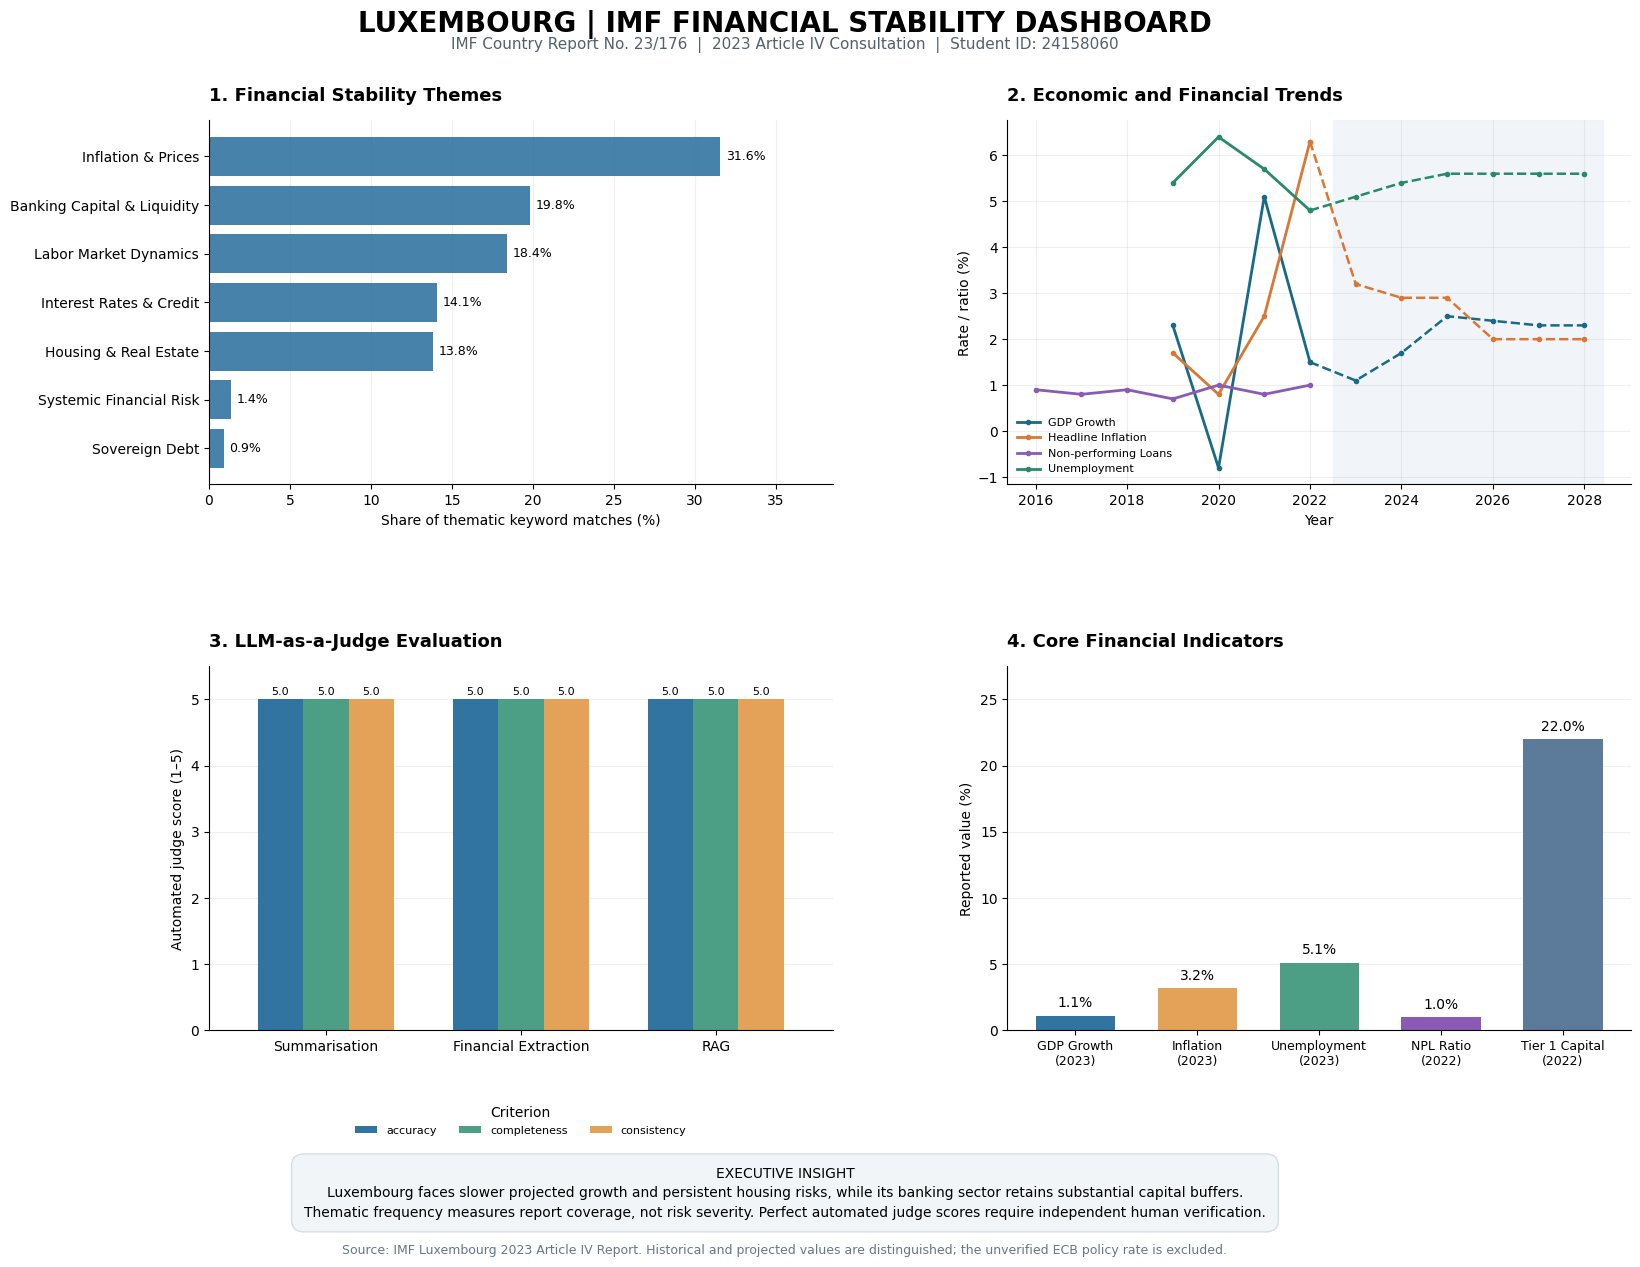

In [22]:
from matplotlib.ticker import MaxNLocator
from matplotlib.patches import Patch

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "figure.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False
})

fig, axes = plt.subplots(2, 2, figsize=(18, 13))
fig.patch.set_facecolor("white")

# Thematic distribution
ax = axes[0, 0]

bars = ax.barh(
    theme_df["Theme"],
    theme_df["Percentage"],
    color="#3274A1",
    alpha=0.9
)

ax.bar_label(bars, fmt="%.1f%%", padding=4, fontsize=9)
ax.set_xlim(0, max(theme_df["Percentage"]) * 1.22)
ax.set_xlabel("Share of thematic keyword matches (%)")
ax.set_title("1. Financial Stability Themes", loc="left", pad=14)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

# Economic trends
ax = axes[0, 1]

colors = {
    "GDP Growth": "#176B87",
    "Headline Inflation": "#D97735",
    "Unemployment": "#278A68",
    "Non-performing Loans": "#8A5AB5"
}

for name, group in trend_long.groupby("Indicator"):
    group = group.sort_values("Year")
    color = colors.get(name, "#444444")

    # Historical data
    historical = group[group["Year"] <= 2022]
    if not historical.empty:
        ax.plot(
            historical["Year"],
            historical["Value"],
            marker="o",
            markersize=3,
            linewidth=2,
            color=color,
            label=name
        )

    # Forecast values, connected to last historical observation
    projected = group[group["Year"] >= 2023]
    if not projected.empty:
        connection = pd.concat([
            historical.tail(1), projected
        ]).sort_values("Year")

        ax.plot(
            connection["Year"],
            connection["Value"],
            linestyle="--",
            marker="o",
            markersize=3,
            linewidth=1.8,
            color=color
        )

ax.axvspan(
    2022.5,
    max(2023, trend_long["Year"].max()) + 0.4,
    color="#EDF2F7",
    alpha=0.75
)

ax.set_title("2. Economic and Financial Trends", loc="left", pad=14)
ax.set_xlabel("Year")
ax.set_ylabel("Rate / ratio (%)")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(alpha=0.2)
ax.legend(fontsize=8, loc="best", frameon=False)

# Automated LLM judge scores
ax = axes[1, 0]

judge_plot = judge_df.set_index("Task")[
    ["accuracy", "completeness", "consistency"]
]

judge_plot.plot(
    kind="bar",
    ax=ax,
    width=0.7,
    color=["#3274A1", "#4C9F85", "#E4A259"]
)

ax.set_ylim(0, 5.5)
ax.set_ylabel("Automated judge score (1–5)")
ax.set_xlabel("")
ax.set_title("3. LLM-as-a-Judge Evaluation", loc="left", pad=14)
ax.tick_params(axis="x", rotation=0)
ax.legend(
    title="Criterion",
    fontsize=8,
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=3
)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", fontsize=8, padding=2)


# Financial indicator comparison
ax = axes[1, 1]

valid = indicator_df.dropna(subset=["Value"]).copy()

labels = [
    f"{row.Indicator}\n({row.Year})"
    for row in valid.itertuples()
]

bars = ax.bar(
    labels,
    valid["Value"],
    color=["#3274A1", "#E4A259", "#4C9F85",
           "#8A5AB5", "#5C7B9B"][:len(valid)],
    width=0.65
)

ax.bar_label(bars, fmt="%.1f%%", padding=4, fontsize=10)
ax.set_ylim(0, max(valid["Value"]) * 1.25)
ax.set_ylabel("Reported value (%)")
ax.set_title("4. Core Financial Indicators", loc="left", pad=14)
ax.tick_params(axis="x", labelsize=9)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

# Main dashboard heading
fig.suptitle(
    "LUXEMBOURG | IMF FINANCIAL STABILITY DASHBOARD",
    fontsize=20,
    fontweight="bold",
    y=0.975
)

fig.text(
    0.5, 0.945,
    "IMF Country Report No. 23/176  |  "
    "2023 Article IV Consultation  |  "
    "Student ID: 24158060",
    ha="center",
    fontsize=11,
    color="#52616B"
)

# Executive insight overlay
fig.text(
    0.5, 0.065,
    "EXECUTIVE INSIGHT\n"
    "Luxembourg faces slower projected growth and persistent housing risks, "
    "while its banking sector retains substantial capital buffers.\n"
    "Thematic frequency measures report coverage, not risk severity. "
    "Perfect automated judge scores require independent human verification.",
    ha="center",
    va="center",
    fontsize=10,
    linespacing=1.5,
    bbox=dict(
        boxstyle="round,pad=0.9",
        facecolor="#F2F5F8",
        edgecolor="#D5DDE5"
    )
)

fig.text(
    0.5, 0.018,
    "Source: IMF Luxembourg 2023 Article IV Report. "
    "Historical and projected values are distinguished; "
    "the unverified ECB policy rate is excluded.",
    ha="center",
    fontsize=9,
    color="#667788"
)

fig.subplots_adjust(
    left=0.18,
    right=0.97,
    top=0.89,
    bottom=0.19,
    hspace=0.50,
    wspace=0.28
)

dashboard_path = output_dir / "luxembourg_imf_dashboard.png"

fig.savefig(
    dashboard_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

Validation results

In [23]:

import json
import pandas as pd
import faiss
from pathlib import Path
from PIL import Image

output_dir = Path("/content/luxembourg_imf")

required_files = [
    "luxembourg_cleaned_text.txt",
    "luxembourg_pages.json",
    "luxembourg_chunks.json",
    "luxembourg_section_summaries.json",
    "luxembourg_executive_summary.json",
    "luxembourg_financial_data.json",
    "luxembourg_indicator_sources.json",
    "luxembourg_themes.json",
    "luxembourg_qualitative_insights.json",
    "luxembourg_trends.json",
    "luxembourg_faiss.index",
    "luxembourg_rag_metadata.json",
    "luxembourg_rag_audit.json",
    "luxembourg_summary_evaluation.csv",
    "luxembourg_financial_evaluation.json",
    "luxembourg_rag_evaluation.json",
    "luxembourg_judge_evaluation.json",
    "luxembourg_imf_dashboard.png"
]

def read_json(name):
    return json.loads(
        (output_dir / name).read_text(encoding="utf-8")
    )

print("FINAL PROJECT VALIDATION\n")

missing = [
    name for name in required_files
    if not (output_dir / name).is_file()
]

print("Required files:", len(required_files))
print("Files available:", len(required_files) - len(missing))
print("Missing files:", missing if missing else "None")

if missing:
    raise FileNotFoundError("Required project files are missing.")

pages = read_json("luxembourg_pages.json")
chunks = read_json("luxembourg_chunks.json")
summaries = read_json("luxembourg_section_summaries.json")
financial = read_json("luxembourg_financial_data.json")
themes = read_json("luxembourg_themes.json")
insights = read_json("luxembourg_qualitative_insights.json")
trends = read_json("luxembourg_trends.json")
rag = read_json("luxembourg_rag_audit.json")
judge = read_json("luxembourg_judge_evaluation.json")

index = faiss.read_index(
    str(output_dir / "luxembourg_faiss.index")
)

metadata = read_json("luxembourg_rag_metadata.json")
summary_eval = pd.read_csv(
    output_dir / "luxembourg_summary_evaluation.csv"
)

financial_eval = read_json("luxembourg_financial_evaluation.json")
rag_eval = read_json("luxembourg_rag_evaluation.json")

required_keys = [
    "country_name",
    "gdp_growth_forecast_pct",
    "headline_inflation_rate_pct",
    "central_bank_policy_rate_pct",
    "non_performing_loan_ratio",
    "unemployment_rate_pct",
    "tier_1_capital_ratio"
]

checks = {
    "PDF pages extracted": len(pages) >= 70,
    "Token-aware chunks": (
        len(chunks) > 0
        and all(0 < c["token_count"] <= 450 for c in chunks)
    ),
    "Seven section summaries": (
        len(summaries) == 7
        and all(
            0 < len(x["summary"].split()) < 100
            for x in summaries.values()
        )
    ),
    "Financial JSON schema": (
        all(k in financial for k in required_keys)
        and financial.get("country_name") == "Luxembourg"
    ),
    "Five numeric indicators": sum(
        isinstance(financial.get(k), (int, float))
        for k in required_keys[1:]
    ) >= 5,
    "Seven financial themes": (
        len(themes.get("themes", {})) == 7
    ),
    "Four trend series": (
        len(trends) == 4
        and all(len(series) >= 3 for series in trends.values())
    ),
    "Qualitative item counts": (
        5 <= len(insights.get("strengths", [])) <= 7
        and 5 <= len(insights.get("vulnerabilities", [])) <= 7
    ),
    "FAISS embedding index": (
        index.ntotal == len(chunks) == len(metadata)
        and index.d == 384
    ),
    "Four RAG audits": (
        len(rag) == 4
        and all(
            len(x.get("retrieved_context", [])) > 0
            for x in rag
        )
    ),
    "Seven summary evaluations": len(summary_eval) == 7,
    "Six financial audits": len(financial_eval) == 6,
    "Four RAG evaluations": len(rag_eval) == 4,
    "Judge summary": all(
        key in judge
        for key in ["Summarisation", "Financial Extraction", "RAG"]
    )
}

with Image.open(output_dir / "luxembourg_imf_dashboard.png") as img:
    width, height = img.size
    dpi = img.info.get("dpi", (0, 0))

checks["High-resolution dashboard"] = (
    width >= 3000 and height >= 2000
    and min(dpi) >= 299
)

print("\nVALIDATION RESULTS\n")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

print("\nFINAL RESULT")
print("Checks passed:", sum(checks.values()), "/", len(checks))
print("Status:", "PASS" if all(checks.values()) else "REVIEW")


FINAL PROJECT VALIDATION

Required files: 18
Files available: 18
Missing files: None

VALIDATION RESULTS

PDF pages extracted: PASS
Token-aware chunks: PASS
Seven section summaries: PASS
Financial JSON schema: PASS
Five numeric indicators: PASS
Seven financial themes: PASS
Four trend series: PASS
Qualitative item counts: PASS
FAISS embedding index: PASS
Four RAG audits: PASS
Seven summary evaluations: PASS
Six financial audits: PASS
Four RAG evaluations: PASS
Judge summary: PASS
High-resolution dashboard: PASS

FINAL RESULT
Checks passed: 15 / 15
Status: PASS
